In [1]:
import matplotlib.pyplot as plt
import numpy as np
import stim

import os 

while 'honeycomb.py' not in os.listdir():
    os.chdir("..")

from honeycomb import CSSHoneycomb

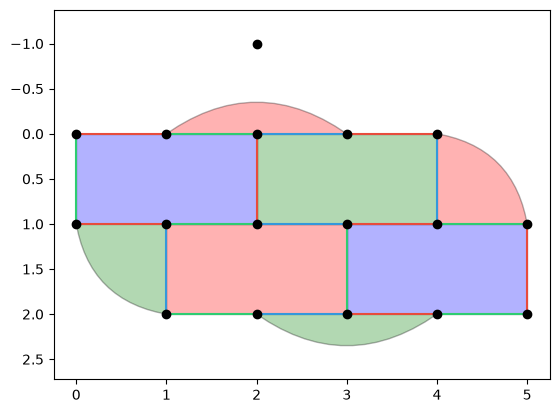

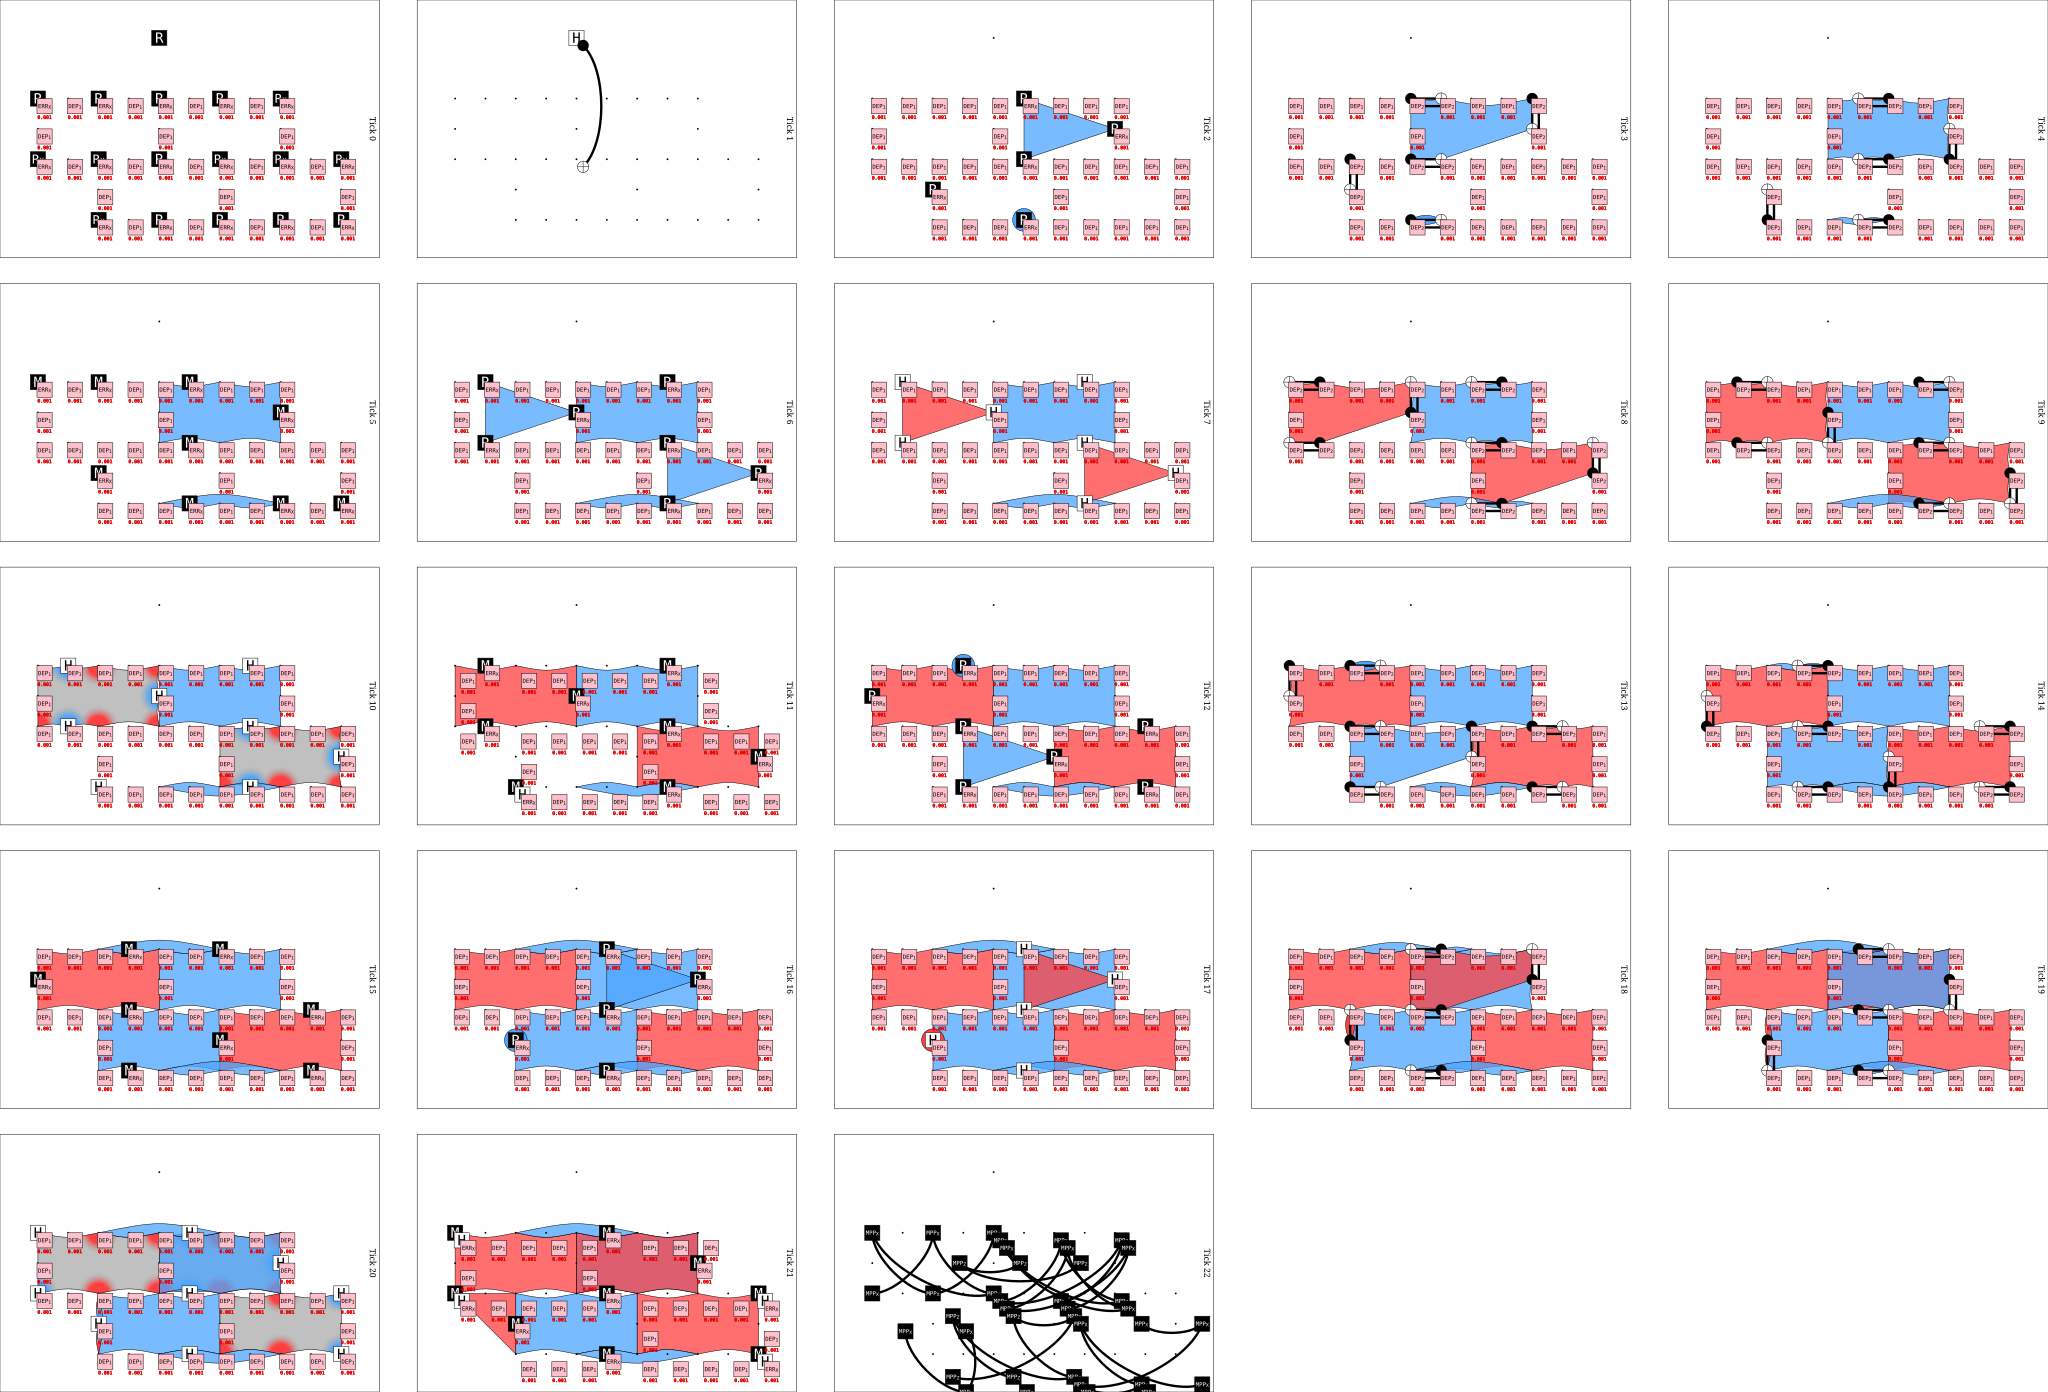

In [2]:
COLOUR_MAP = {
    'r' : 'red',
    'g' : 'green',
    'b' : 'blue'
}

def measurement_cycle(honey: CSSHoneycomb, cycle=["rZ", "gX", "bZ", "rX", "gZ", "bX"]):
    """
    measure our stabilizers
    """

    string = ""
    for m in cycle:
        
        if m == "gZ":
            print("" ,end="")
        
        colour = COLOUR_MAP[m[0]]
        flavour = m[1]

        string += f"#{colour}{flavour}\n"
        string += honey.get_measurement(colour, flavour) + "\n"
        string += honey.tick()
        
        # detectors = honey.get_detectors()
        # string += honey.write_detectors(detectors, honey.clock)
        
        # print(detectors)
    
    return string

s = CSSHoneycomb(ncols=5, nrows=3, config_filepath="config/5x3.json")
s.plot_surface()
string = s.initialise_circuit()
string += s.prepare_qubits()
string += measurement_cycle(s, cycle=["bZ", "rX", "gZ", "bX"])
string += s.write_logical_observable(string, "blue", "X")
string += s.final_readout()

circuit = stim.Circuit(string)
circuit.diagram("detslice-with-ops-svg")